La base tiene 10.763 créditos (de nov-2024 a abr-2026) y 23 columnas: datos del crédito (tipo, monto, plazo, cuota), del cliente (edad, tipo laboral, salario), su historial en Datacrédito (puntaje, saldos, consultas, créditos por sector) y la variable objetivo **Pago_atiempo** (1 = pagó a tiempo, 0 = incumplió).

### **1. Preprocesamiento**

#### **Librerías**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import roc_auc_score

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)

#### **1.1 Carga y revisión inicial**

Se reutilizan los datos originales cargados por `cargar_datos.py`. Se trabaja sobre una copia para no modificar el DataFrame original.

In [3]:
from cargar_datos import datos as db

print('Filas y columnas:', db.shape)
db.head()

Datos cargados desde: C:\Users\kamil\Desktop\Universidad\Semestre 10\Machine Learning\Trabajo final\mlops_mkmena\BD_creditos.xlsx

Dimensiones: 10,763 filas y 23 columnas

Vista previa (primeras 10 filas, datos originales):
 tipo_credito      fecha_prestamo  capital_prestado  plazo_meses  edad_cliente  tipo_laboral  salario_cliente  total_otros_prestamos  cuota_pactada   puntaje  puntaje_datacredito  cant_creditosvigentes  huella_consulta  saldo_mora  saldo_total  saldo_principal  saldo_mora_codeudor  creditos_sectorFinanciero  creditos_sectorCooperativo  creditos_sectorReal  promedio_ingresos_datacredito tendencia_ingresos  Pago_atiempo
            4 2025-01-07 14:40:36         1852560.0           12            32      Empleado          3500000                1000000         128650 95.227787                795.0                      0                2         0.0          0.0              NaN                  NaN                          0                           0                  

,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,puntaje_datacredito,cant_creditosvigentes,huella_consulta,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,4,2025-01-07 14:40:36,1852560.0,12,32,Empleado,3500000,1000000,128650,95.227787,795.0,0,2,0.0,0.0,NaN,NaN,0,0,0,916148.0,Creciente,1
1,4,2025-01-09 11:18:48,3181080.0,6,34,Empleado,5000000,2000000,441817,95.227787,796.0,0,7,0.0,0.0,NaN,NaN,0,0,0,4473774.0,Creciente,1
2,9,2024-12-26 18:52:57,670200.0,5,34,Independiente,5000000,2000000,108632,95.227787,727.0,5,0,0.0,274561.0,274561.0,NaN,2,0,1,NaN,NaN,1
3,9,2024-12-04 14:20:50,506806.8,2,25,Independiente,3000000,900000,199684,95.227787,864.0,8,1,0.0,27564.0,27564.0,NaN,1,0,6,NaN,NaN,1
4,4,2025-04-30 18:41:57,999780.0,10,26,Empleado,2000000,600000,92509,95.227787,771.0,0,3,0.0,0.0,NaN,NaN,0,0,0,61000.0,Creciente,1


In [4]:
resumen = pd.DataFrame({'tipo': db.dtypes.astype(str), 'valores únicos': db.nunique()})
resumen

,tipo,valores únicos
tipo_credito,int64,6
fecha_prestamo,datetime64[us],10758
capital_prestado,float64,7306
plazo_meses,int64,18
edad_cliente,int64,54
tipo_laboral,str,2
salario_cliente,int64,1385
total_otros_prestamos,int64,1538
cuota_pactada,int64,9836
puntaje,float64,248


#### **1.2 Caracterización de las variables**

Clasificamos cada variable por su naturaleza:

| Variable | Naturaleza | Comentario |
|---|---|---|
| `tipo_credito` | Nominal politómica | Llega como número (4, 6, 7, 9, 10, 68) pero es una categoría, no una cantidad |
| `tipo_laboral` | Nominal dicotómica | Empleado / Independiente |
| `tendencia_ingresos` | Ordinal | Decreciente < Estable < Creciente |
| `Pago_atiempo` | Dicotómica (objetivo) | 1 = paga a tiempo, 0 = incumple |
| `fecha_prestamo` | Fecha | Llega como texto |
| `capital_prestado`, `salario_cliente`, `total_otros_prestamos`, `cuota_pactada`, `saldo_*`, `promedio_ingresos_datacredito` | Numéricas continuas (montos) | |
| `plazo_meses`, `edad_cliente`, `cant_creditosvigentes`, `huella_consulta`, `creditos_sector*` | Numéricas discretas (conteos) | |
| `puntaje`, `puntaje_datacredito` | Numéricas (puntajes) | `puntaje` es sospechosa, se revisa en la sección 3 |

#### **1.3 Valores nulos**

Primero miramos cuántos nulos hay y luego buscamos "falsos nulos" (texto como *NULL*, *N/A* o *-*) que pandas no cuenta como nulos.

In [5]:
nulos = pd.DataFrame({'nulos': db.isnull().sum(), '% nulos': (db.isnull().mean() * 100).round(2)})
nulos[nulos['nulos'] > 0]

,nulos,% nulos
puntaje_datacredito,6,0.06
saldo_mora,156,1.45
saldo_total,156,1.45
saldo_principal,405,3.76
saldo_mora_codeudor,590,5.48
promedio_ingresos_datacredito,2930,27.22
tendencia_ingresos,2932,27.24


In [6]:
marcadores = ['', 'NA', 'N/A', 'NULL', 'null', 'None', '-', '--', 'sin dato', 'no informado']

print('Falsos nulos (texto) por columna de texto:')
for col in db.select_dtypes(exclude='number').columns:
    print(col, ':', db[col].astype(str).str.strip().isin(marcadores).sum())

Falsos nulos (texto) por columna de texto:
fecha_prestamo : 0
tipo_laboral : 0
tendencia_ingresos : 0


No hay falsos nulos: los faltantes ya vienen como nulos reales. Se concentran en `promedio_ingresos_datacredito` y `tendencia_ingresos` (~27%) y en los saldos (1% a 5%). Revisamos si los faltantes siguen algún patrón o son aleatorios.

In [7]:
print('Faltan promedio de ingresos y tendencia a la vez:',
      (db['promedio_ingresos_datacredito'].isnull() & db['tendencia_ingresos'].isnull()).sum())
print()
print('% sin promedio de ingresos según tipo laboral:')
print((db.groupby('tipo_laboral')['promedio_ingresos_datacredito'].apply(lambda s: s.isnull().mean()) * 100).round(1))

Faltan promedio de ingresos y tendencia a la vez: 2930

% sin promedio de ingresos según tipo laboral:
tipo_laboral
Empleado         19.0
Independiente    41.0
Name: promedio_ingresos_datacredito, dtype: float64


Los dos faltan casi siempre juntos (2.930 casos) y faltan mucho más en independientes (41%) que en empleados (19%). Esto parece falta de historial de ingresos reportado y no azar.

#### **1.4 Revisión de inconsistencias**

Revisamos cada variable buscando valores imposibles o raros.

**Edad (edad_cliente).**

In [8]:
print(db['edad_cliente'].describe(), '\n')
print('Edades más altas:')
print(db['edad_cliente'].value_counts().sort_index().tail(5))
print('\nEdades mayores a 100:', (db['edad_cliente'] > 100).sum())

count    10763.000000
mean        43.948620
std         15.060877
min         19.000000
25%         33.000000
50%         42.000000
75%         53.000000
max        123.000000
Name: edad_cliente, dtype: float64 

Edades más altas:
edad_cliente
68     109
69      55
121      4
122    144
123      2
Name: count, dtype: int64

Edades mayores a 100: 150


Hay **150 clientes con 121, 122 o 123 años** (144 con exactamente 122). Es imposible, parece un valor de relleno o un error de digitación. Las edades normales llegan hasta ~69.

**Salario (salario_cliente).**

In [9]:
print(db['salario_cliente'].describe().round(0), '\n')
print('Salarios iguales a 0:', (db['salario_cliente'] == 0).sum())
print('Salarios mayores a 100 millones:', (db['salario_cliente'] > 100_000_000).sum())
print('Salarios entre 1 y 100.000:', ((db['salario_cliente'] > 0) & (db['salario_cliente'] < 100_000)).sum())
print('Los 5 más altos:', db['salario_cliente'].nlargest(5).tolist())

count    1.076300e+04
mean     1.721643e+07
std      3.554767e+08
min      0.000000e+00
25%      2.000000e+06
50%      3.000000e+06
75%      4.875808e+06
max      2.200000e+10
Name: salario_cliente, dtype: float64 

Salarios iguales a 0: 24
Salarios mayores a 100 millones: 74
Salarios entre 1 y 100.000: 7
Los 5 más altos: [22000000000, 16991100000, 13258352050, 12450806583, 8252584000]


La mediana es 3 millones, pero el máximo es 22 mil millones: hay 24 salarios en 0 y 74 por encima de 100 millones (valores irreales, probablemente errores de digitación). El tope de 100 millones es un supuesto. Además hay 7 salarios entre 1 y 100.000 (el mínimo es 1.000), que podrían ser errores por falta de ceros; como no es seguro, no se tocan y quedan como pendiente.

**Puntaje de Datacrédito (puntaje_datacredito).**

In [10]:
print(db['puntaje_datacredito'].describe().round(1), '\n')
print('Valores menores a 150:')
print(db[db['puntaje_datacredito'] < 150]['puntaje_datacredito'].value_counts())
print('\nValores mayores a 950:', (db['puntaje_datacredito'] > 950).sum(), '| máximo:', db['puntaje_datacredito'].max())

count    10757.0
mean       780.8
std        104.9
min         -7.0
25%        757.0
50%        791.0
75%        825.0
max        999.0
Name: puntaje_datacredito, dtype: float64 

Valores menores a 150:
puntaje_datacredito
 0.0    145
 7.0      1
-7.0      1
Name: count, dtype: int64

Valores mayores a 950: 6 | máximo: 999.0


El puntaje normal está entre ~290 y 999. Hay 147 valores menores a 150 (145 en 0, uno en 7 y uno en -7), que son códigos de "sin puntaje" y no puntajes reales. Los valores mayores a 950 (máximo 999) **se conservan**: no hay una regla de negocio que los invalide.

**Tendencia de ingresos (tendencia_ingresos).**

In [11]:
print(db['tendencia_ingresos'].value_counts(dropna=False).head(8))

categorias = ['Creciente', 'Estable', 'Decreciente']
basura = db[db['tendencia_ingresos'].notna() & ~db['tendencia_ingresos'].isin(categorias)]
print('\nValores que no son una tendencia:', len(basura))
print('Ejemplos:', basura['tendencia_ingresos'].head(10).tolist())

tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
Name: count, dtype: int64

Valores que no son una tendencia: 58
Ejemplos: [8315, 8315, 0, 158042, 3978, 9147, 8315, 168750, -28589, 8315]


Esta columna debería tener solo 3 categorías (Creciente, Estable, Decreciente), pero hay **58 registros con números** (8315, 0, 158042, -28589...). No son tendencias: parecen valores que se corrieron de otra columna. Se tratan como nulos.

**Tipo de crédito, montos y fechas.**

In [12]:
print(db['tipo_credito'].value_counts(), '\n')
print('Créditos de tipos con menos de 25 casos:', db['tipo_credito'].isin([6, 7, 68]).sum(), '\n')
print('Mayores valores de total_otros_prestamos:', db['total_otros_prestamos'].nlargest(5).tolist())
print('Registros con total_otros_prestamos > 1.000 millones:', (db['total_otros_prestamos'] > 1_000_000_000).sum(), '\n')
fechas = pd.to_datetime(db['fecha_prestamo'])
print('Rango de fechas:', fechas.min(), '->', fechas.max())

tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64 

Créditos de tipos con menos de 25 casos: 24 

Mayores valores de total_otros_prestamos: [6787675263, 4974345404, 4316463703, 3918433000, 3758729000]
Registros con total_otros_prestamos > 1.000 millones: 13 

Rango de fechas: 2024-11-26 09:17:04 -> 2026-04-26 18:43:52


- `tipo_credito`: el 72% es tipo 4 y el 27% tipo 9. Los tipos 6, 7 y 68 tienen muy pocos casos (21, 2 y 1), no se pueden analizar por separado.
- `total_otros_prestamos`: hay 13 registros por encima de 1.000 millones (máximo 6.788 millones). Son muy extremos, pero no podemos saber si son errores, así que no se tocan por ahora.
- Las fechas son coherentes (ninguna fecha imposible).

#### **1.5 Duplicados**

In [13]:
print('Filas duplicadas:', db.duplicated().sum())

Filas duplicadas: 0


No hay filas duplicadas, no hay nada que eliminar.

### **2. Limpieza**

La regla que usamos: **los valores imposibles se convierten en nulo y no se elimina la fila**. Si se borra la fila se pierde la información de las otras 22 columnas, y además en producción el modelo tiene que poder puntuar cualquier solicitud que llegue. Los nulos se imputan después, en el pipeline de entrenamiento (no aquí, para no usar información de los datos de prueba).

Guardamos en `registro` cuántos valores afecta cada regla.

In [14]:
datos = db.copy()
registro = []

def invalidar(columna, mascara, regla):
    registro.append((regla, int(mascara.sum())))
    datos.loc[mascara, columna] = np.nan

Pasamos la fecha a tipo fecha y `tipo_credito` a categoría (es un código, no una cantidad).

In [15]:
datos['fecha_prestamo'] = pd.to_datetime(datos['fecha_prestamo'])
datos['tipo_credito'] = datos['tipo_credito'].astype(str)
datos.dtypes[['fecha_prestamo', 'tipo_credito']]

fecha_prestamo    datetime64[us]
tipo_credito                 str
dtype: object

Edades fuera de 18 a 100 años pasan a nulo.

In [16]:
invalidar('edad_cliente', (datos['edad_cliente'] < 18) | (datos['edad_cliente'] > 100), 'edad fuera de 18-100')
print(datos['edad_cliente'].describe().round(1))

count    10613.0
mean        42.8
std         11.9
min         19.0
25%         33.0
50%         42.0
75%         52.0
max         69.0
Name: edad_cliente, dtype: float64


Salarios iguales a 0 o mayores a 100 millones pasan a nulo.

In [17]:
invalidar('salario_cliente', (datos['salario_cliente'] <= 0) | (datos['salario_cliente'] > 100_000_000), 'salario <= 0 o > 100 millones')
print(datos['salario_cliente'].describe().round(0))

count       10665.0
mean      4115411.0
std       5102723.0
min          1000.0
25%       2000000.0
50%       3000000.0
75%       4760000.0
max      95985077.0
Name: salario_cliente, dtype: float64


Puntajes de Datacrédito menores a 150 pasan a nulo (los mayores a 950 se conservan).

In [18]:
invalidar('puntaje_datacredito', datos['puntaje_datacredito'] < 150, 'puntaje_datacredito < 150')
print(datos['puntaje_datacredito'].describe().round(1))

count    10610.0
mean       791.6
std         50.9
min        287.0
25%        758.0
50%        792.0
75%        826.0
max        999.0
Name: puntaje_datacredito, dtype: float64


Los valores de `tendencia_ingresos` que no son Creciente, Estable o Decreciente pasan a nulo.

In [19]:
invalidar('tendencia_ingresos', datos['tendencia_ingresos'].notna() & ~datos['tendencia_ingresos'].isin(categorias), 'tendencia_ingresos no es una categoría')
print(datos['tendencia_ingresos'].value_counts(dropna=False))

tendencia_ingresos
Creciente      5294
NaN            2990
Decreciente    1291
Estable        1188
Name: count, dtype: int64


Resumen de lo que se convirtió en nulo. Ninguna fila se eliminó (seguimos con 10.763) y la base original `db` queda intacta.

In [20]:
print('Filas:', len(datos))
pd.DataFrame(registro, columns=['Regla', 'Valores convertidos a nulo'])

Filas: 10763


,Regla,Valores convertidos a nulo
0,edad fuera de 18-100,150
1,salario <= 0 o > 100 millones,98
2,puntaje_datacredito < 150,147
3,tendencia_ingresos no es una categoría,58


**Qué NO se tocó y por qué:**
- Puntajes de Datacrédito mayores a 950: no hay regla de negocio que los invalide.
- Montos muy asimétricos (`capital_prestado`, `saldos`, `total_otros_prestamos`): son valores reales de dinero, se transforman con logaritmo en lugar de eliminarlos.
- `saldo_mora` y `saldo_mora_codeudor`: casi todo ceros, los pocos valores positivos son justo los clientes en mora (ver sección 4.1).
- Tipos de crédito raros (6, 7 y 68): se agrupan como "otros" al codificar.

### **3. Selección de variables**

Antes de analizar, revisamos si alguna variable no debería usarse para predecir. Ninguna es un identificador ni una constante, pero **`puntaje`** llamó la atención porque casi explica por sí sola la variable objetivo.

In [21]:
print('Correlación de puntaje con Pago_atiempo:', round(db['puntaje'].corr(db['Pago_atiempo']), 3), '\n')
print(db.groupby('Pago_atiempo')['puntaje'].describe().round(1), '\n')
print('% de registros con el puntaje en su valor máximo:', round((db['puntaje'] == db['puntaje'].max()).mean() * 100, 1))
print('AUC usando solo puntaje para detectar incumplimiento:', roc_auc_score(db['Pago_atiempo'] == 0, -db['puntaje']))

Correlación de puntaje con Pago_atiempo: 0.923 

                count  mean   std   min   25%   50%   75%   max
Pago_atiempo                                                   
0               511.0  23.1  26.1 -38.0  -3.6  25.4  47.6  62.7
1             10252.0  94.6   2.9  63.8  95.2  95.2  95.2  95.2 

% de registros con el puntaje en su valor máximo: 87.4
AUC usando solo puntaje para detectar incumplimiento: 1.0


Resultado:
- La correlación con el objetivo es 0,92, y las demás variables no pasan de 0,12.
- Quienes incumplen nunca superan 62,7 de puntaje, y quienes pagan tienen casi siempre 95,23 (el 87% de los registros está en ese tope).
- Con **solo esa variable** se separan las dos clases a la perfección (AUC = 1,0). Eso no pasa en riesgo de crédito real.

Esto es señal de **fuga de datos (data leakage)**: probablemente `puntaje` se calcula con información posterior al desembolso (por ejemplo, el comportamiento de pago). Si es así, no sirve para decidir un crédito nuevo, porque en ese momento todavía no existe. **Se excluye del modelo.** Queda pendiente confirmar con quien conozca los datos cuándo se calcula; mientras tanto la exclusión es la opción segura (si fuera legítima solo se pierde capacidad predictiva; si es fuga y se incluye, el modelo no sirve en producción).

Variables que se eliminan o no entran como predictoras:
- `puntaje`: posible fuga de datos.
- `fecha_prestamo`: no se usa como predictor porque el comportamiento cambia con el tiempo; se conserva para el análisis temporal y para el monitoreo de drift.

In [22]:
datos = datos.drop(columns='puntaje')
print('Columnas:', datos.shape[1])

Columnas: 22


### **4. Análisis univariable**

In [23]:
numericas = ['capital_prestado', 'plazo_meses', 'edad_cliente', 'salario_cliente', 'total_otros_prestamos',
             'cuota_pactada', 'puntaje_datacredito', 'cant_creditosvigentes', 'huella_consulta', 'saldo_mora',
             'saldo_total', 'saldo_principal', 'saldo_mora_codeudor', 'creditos_sectorFinanciero',
             'creditos_sectorCooperativo', 'creditos_sectorReal', 'promedio_ingresos_datacredito']
categoricas = ['tipo_credito', 'tipo_laboral', 'tendencia_ingresos']

#### **4.1 Variables numéricas**

Con `describe()` y otras medidas de tendencia central y dispersión (moda, rango, IQR, varianza, asimetría y curtosis).

In [24]:
datos[numericas].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
capital_prestado,10763.0,2434315.0,1909642.8,360000.0,1224831.0,1921920.0,3084840.0,4.144415e+07
plazo_meses,10763.0,10.6,6.6,2.0,6.0,10.0,12.0,9.000000e+01
edad_cliente,10613.0,42.8,11.9,19.0,33.0,42.0,52.0,6.900000e+01
salario_cliente,10665.0,4115411.0,5102723.1,1000.0,2000000.0,3000000.0,4760000.0,9.598508e+07
total_otros_prestamos,10763.0,6238869.6,118418316.9,0.0,500000.0,1000000.0,2000000.0,6.787675e+09
cuota_pactada,10763.0,243617.4,210493.7,23944.0,121041.5,182863.0,287833.5,3.816752e+06
puntaje_datacredito,10610.0,791.6,50.9,287.0,758.0,792.0,826.0,9.990000e+02
cant_creditosvigentes,10763.0,5.7,4.0,0.0,3.0,5.0,8.0,6.200000e+01
huella_consulta,10763.0,4.2,3.1,0.0,2.0,4.0,6.0,2.900000e+01
saldo_mora,10607.0,7.7,226.0,0.0,0.0,0.0,0.0,1.253400e+04


In [25]:
estadisticos = pd.DataFrame({
    'moda': datos[numericas].mode().iloc[0],
    'rango': datos[numericas].max() - datos[numericas].min(),
    'IQR': datos[numericas].quantile(0.75) - datos[numericas].quantile(0.25),
    'varianza': datos[numericas].var(),
    'asimetría': datos[numericas].skew(),
    'curtosis': datos[numericas].kurtosis(),
    '% ceros': (datos[numericas] == 0).mean() * 100
})
estadisticos.round(1)

,moda,rango,IQR,varianza,asimetría,curtosis,% ceros
capital_prestado,1200000.0,4.108415e+07,1860009.0,3.646735e+12,3.7,35.3,0.0
plazo_meses,6.0,8.800000e+01,6.0,4.400000e+01,2.5,7.8,0.0
edad_cliente,40.0,5.000000e+01,19.0,1.427000e+02,0.3,-0.9,0.0
salario_cliente,3000000.0,9.598408e+07,2760000.0,2.603778e+13,8.7,113.2,0.0
total_otros_prestamos,2000000.0,6.787675e+09,1500000.0,1.402290e+16,38.5,1719.3,4.1
cuota_pactada,205990.0,3.792808e+06,166792.0,4.430760e+10,3.8,26.7,0.0
puntaje_datacredito,783.0,7.120000e+02,68.0,2.587600e+03,-0.7,5.2,0.0
cant_creditosvigentes,4.0,6.200000e+01,5.0,1.580000e+01,1.8,8.6,3.8
huella_consulta,2.0,2.900000e+01,4.0,9.400000e+00,1.5,4.0,6.5
saldo_mora,0.0,1.253400e+04,0.0,5.105570e+04,40.6,1845.7,98.0


Lo que se ve:
- Los **montos** (`salario_cliente`, `total_otros_prestamos`, `saldos`, `capital_prestado`, `cuota_pactada`) tienen asimetría positiva muy fuerte (de 3,7 hasta 95): la mayoría de valores es baja y hay pocos muy altos. No son gaussianas.
- `saldo_mora` (98% de ceros) y `saldo_mora_codeudor` (94%) son casi constantes en 0: solo unos pocos clientes tienen mora.
- `creditos_sectorCooperativo` (82% ceros) y `creditos_sectorReal` (41%) también tienen muchos ceros.
- `edad_cliente` es la única con asimetría cercana a 0 (0,3) y `puntaje_datacredito` es parecida a una campana con cola hacia los valores bajos (-0,7).

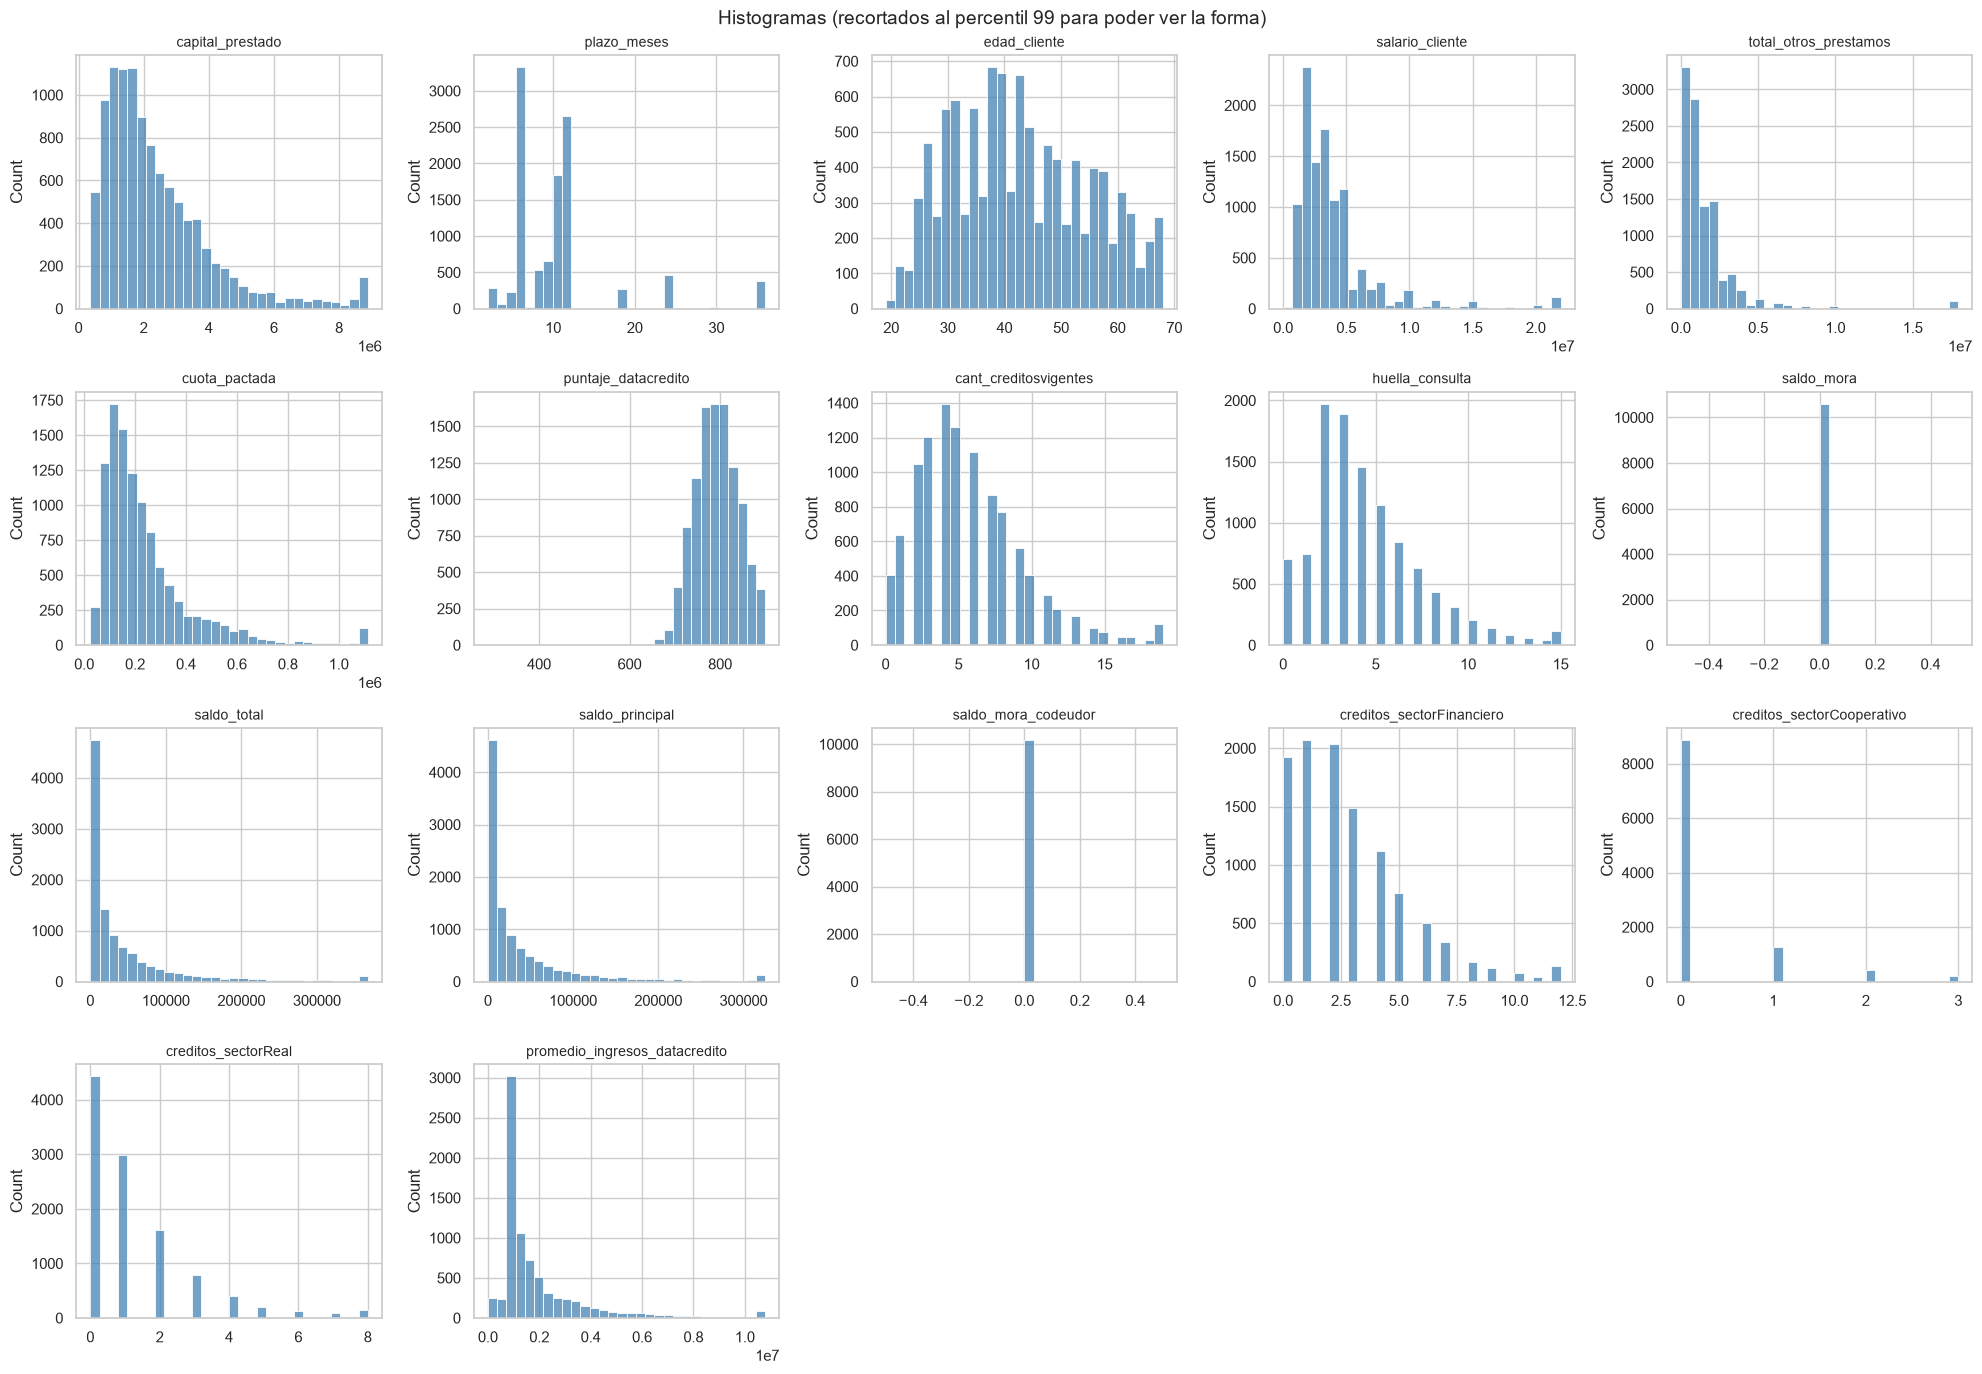

In [26]:
fig, axes = plt.subplots(4, 5, figsize=(20, 14))
for ax, col in zip(axes.ravel(), numericas):
    serie = datos[col].dropna()
    sns.histplot(serie.clip(upper=serie.quantile(0.99)), bins=30, ax=ax, color='steelblue')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
for ax in axes.ravel()[len(numericas):]:
    ax.axis('off')
plt.suptitle('Histogramas (recortados al percentil 99 para poder ver la forma)', fontsize=14)
plt.tight_layout()
plt.show()

Tipo de distribución aproximado:
- **Asimétrica a la derecha (tipo log-normal):** `capital_prestado`, `cuota_pactada`, `salario_cliente`, `total_otros_prestamos`, `saldos`, `promedio_ingresos_datacredito`.
- **Conteos con cola a la derecha:** `plazo_meses`, `cant_creditosvigentes`, `huella_consulta`, `creditos_sector*`.
- **Casi simétrica:** `edad_cliente` (entre 19 y 69) y `puntaje_datacredito`.
- **Concentrada en cero:** `saldo_mora` y `saldo_mora_codeudor`.

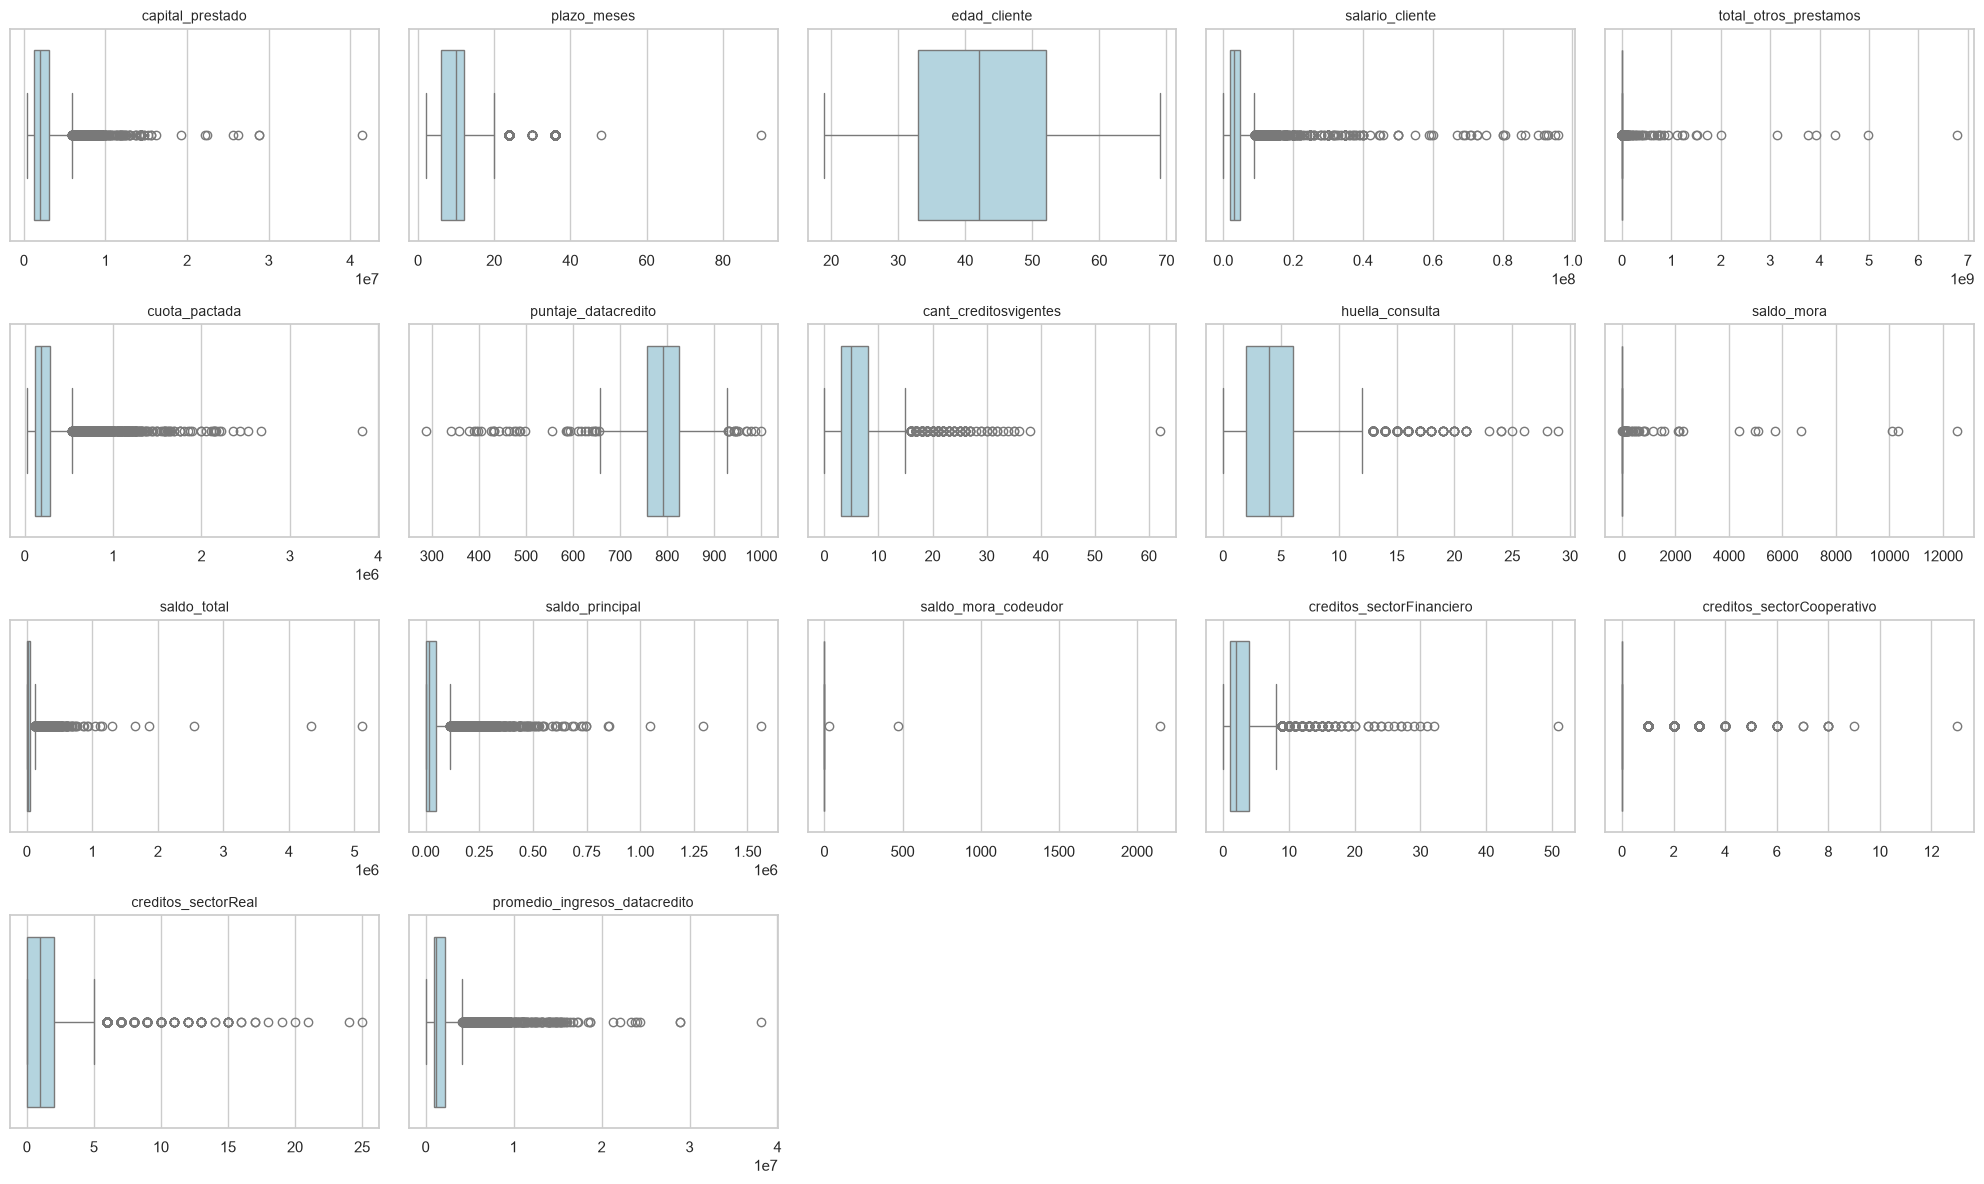

In [27]:
fig, axes = plt.subplots(4, 5, figsize=(20, 12))
for ax, col in zip(axes.ravel(), numericas):
    sns.boxplot(x=datos[col], ax=ax, color='lightblue')
    ax.set_title(col, fontsize=10)
    ax.set_xlabel('')
for ax in axes.ravel()[len(numericas):]:
    ax.axis('off')
plt.tight_layout()
plt.show()

**Valores atípicos.** Contamos cuántos marca la regla del IQR (1,5 veces el rango intercuartil) y la del Z-score (mayor a 3).

In [28]:
def contar_atipicos(serie):
    s = serie.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    por_iqr = ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()
    por_z = (((s - s.mean()) / s.std()).abs() > 3).sum()
    return pd.Series({'atípicos IQR': por_iqr, 'atípicos Z>3': por_z})

datos[numericas].apply(contar_atipicos).T

,atípicos IQR,atípicos Z>3
capital_prestado,550,202
plazo_meses,869,387
edad_cliente,0,0
salario_cliente,702,150
total_otros_prestamos,589,26
cuota_pactada,765,212
puntaje_datacredito,49,38
cant_creditosvigentes,242,151
huella_consulta,216,156
saldo_mora,55,18


Las dos reglas marcan muchos valores en casi todos los montos, pero **no se eliminan**:
- En variables con muchos ceros (`saldo_mora`, `saldo_mora_codeudor`) el IQR es 0, entonces cualquier valor distinto de 0 queda como "atípico". Son justo los clientes en mora, que es la señal más importante.
- En los montos, los valores altos son dinero real y la asimetría se corrige con logaritmo. Los valores realmente imposibles (edades, salarios, puntajes) ya se trataron en la sección 2.
- Las pocas excepciones sin explicación (por ejemplo `total_otros_prestamos` por encima de 1.000 millones) se dejan y su efecto se reduce con el logaritmo.

#### **4.2 Variables categóricas**

In [29]:
for col in categoricas:
    frec = datos[col].fillna('Faltante').value_counts()
    print(pd.DataFrame({'n': frec, '%': (frec / len(datos) * 100).round(1)}), '\n')

                 n     %
tipo_credito            
4             7747  72.0
9             2876  26.7
10             116   1.1
6               21   0.2
7                2   0.0
68               1   0.0 

                  n     %
tipo_laboral             
Empleado       6754  62.8
Independiente  4009  37.2 

                       n     %
tendencia_ingresos            
Creciente           5294  49.2
Faltante            2990  27.8
Decreciente         1291  12.0
Estable             1188  11.0 



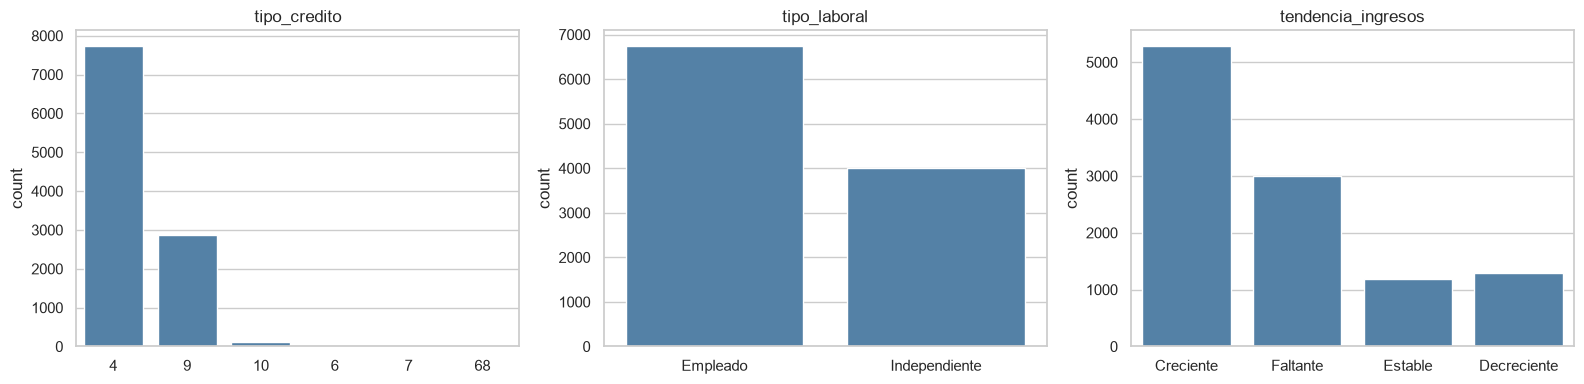

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, categoricas):
    sns.countplot(x=datos[col].fillna('Faltante'), ax=ax, color='steelblue')
    ax.set_title(col)
    ax.set_xlabel('')
plt.tight_layout()
plt.show()

- `tipo_credito`: dominada por los tipos 4 (72%) y 9 (27%). El resto casi no tiene casos.
- `tipo_laboral`: 63% empleados y 37% independientes.
- `tendencia_ingresos`: 49% Creciente, 12% Decreciente, 11% Estable y 28% faltante (2.990, incluyendo los 58 que antes eran basura).

### **5. Análisis bivariable (contra la variable objetivo)**

#### **5.1 Variable objetivo**

Pago_atiempo
1    10252
0      511
Name: count, dtype: int64
Pago_atiempo
1    95.25
0     4.75
Name: proportion, dtype: float64


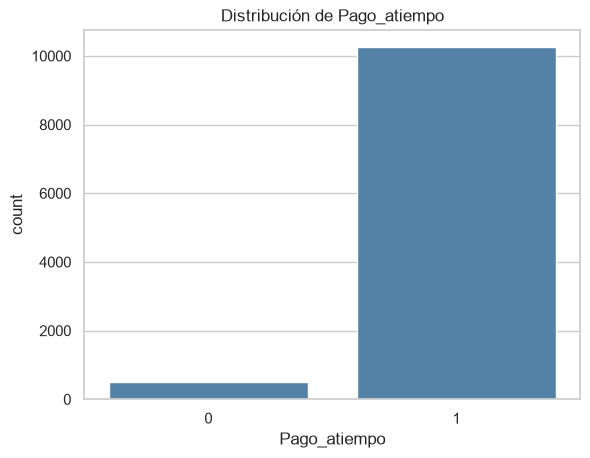

In [31]:
print(datos['Pago_atiempo'].value_counts())
print((datos['Pago_atiempo'].value_counts(normalize=True) * 100).round(2))

sns.countplot(x='Pago_atiempo', data=datos, color='steelblue')
plt.title('Distribución de Pago_atiempo')
plt.show()

Solo el **4,75%** de los créditos (511) incumple. La clase está muy desbalanceada: un modelo que siempre diga "paga a tiempo" tendría 95% de acierto sin servir para nada. Por eso, más adelante no se evalúa con *accuracy* sino con recall, precisión y F1 de la clase de incumplimiento.

#### **5.2 Variables numéricas según el objetivo**

In [32]:
datos.groupby('Pago_atiempo')[numericas].median().T.round(1)

Pago_atiempo,0,1
capital_prestado,2268000.0,1908446.4
plazo_meses,10.0,10.0
edad_cliente,37.0,42.0
salario_cliente,3000000.0,3000000.0
total_otros_prestamos,900000.0,1000000.0
cuota_pactada,199002.0,182576.0
puntaje_datacredito,769.0,792.0
cant_creditosvigentes,5.0,5.0
huella_consulta,5.0,4.0
saldo_mora,0.0,0.0


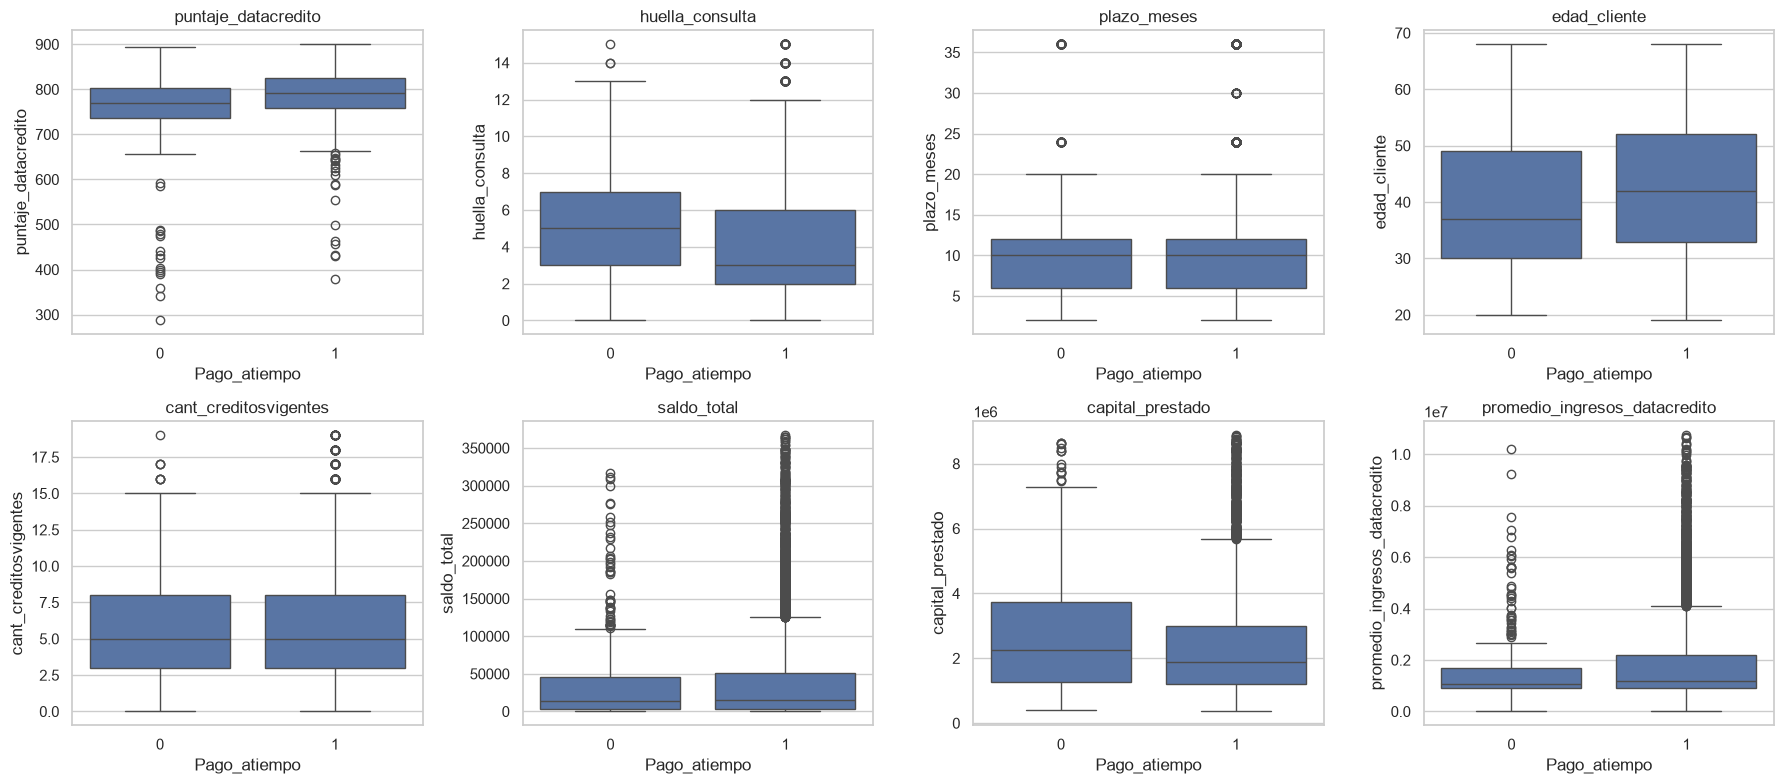

In [33]:
columnas = ['puntaje_datacredito', 'huella_consulta', 'plazo_meses', 'edad_cliente',
            'cant_creditosvigentes', 'saldo_total', 'capital_prestado', 'promedio_ingresos_datacredito']
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.ravel(), columnas):
    visible = datos[datos[col] <= datos[col].quantile(0.99)]
    sns.boxplot(data=visible, x='Pago_atiempo', y=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Las medianas de ambos grupos son muy parecidas en casi todas las variables. Las diferencias más claras: quienes incumplen tienen **menor puntaje de Datacrédito** (mediana 769 vs 792), **más consultas** (5 vs 4), **menor edad** (37 vs 42 años) y piden **montos algo más altos** (mediana 2,27 vs 1,91 millones). Se necesita mirar por rangos para ver más.

#### **5.3 Tasa de pago a tiempo por grupos**

In [34]:
def tasa_pago(columna, grupos=None):
    agrupador = datos[columna].fillna('Faltante') if grupos is None else pd.cut(datos[columna], grupos)
    return datos.groupby(agrupador, observed=True)['Pago_atiempo'].agg(clientes='count', tasa_pago='mean').round(3)

for col in ['tipo_laboral', 'tendencia_ingresos', 'tipo_credito']:
    display(tasa_pago(col))

,clientes,tasa_pago
tipo_laboral,,
Empleado,6754,0.957
Independiente,4009,0.945


,clientes,tasa_pago
tendencia_ingresos,,
Creciente,5294,0.961
Decreciente,1291,0.937
Estable,1188,0.954
Faltante,2990,0.944


,clientes,tasa_pago
tipo_credito,,
10,116,0.974
4,7747,0.953
6,21,0.571
68,1,1.000
7,2,1.000
9,2876,0.953


In [35]:
display(tasa_pago('puntaje_datacredito', [0, 700, 750, 800, 850, 1000]))
display(tasa_pago('huella_consulta', [-1, 2, 5, 10, 50]))
display(tasa_pago('plazo_meses', [0, 6, 12, 24, 100]))
display(tasa_pago('edad_cliente', [17, 30, 40, 50, 60, 101]))

print('Con mora (saldo_mora > 0) vs sin mora:')
display(datos.groupby(datos['saldo_mora'].fillna(0) > 0)['Pago_atiempo'].agg(clientes='count', tasa_pago='mean').round(3))

,clientes,tasa_pago
puntaje_datacredito,,
"(0, 700]",232,0.849
"(700, 750]",1937,0.923
"(750, 800]",3889,0.955
"(800, 850]",3239,0.968
"(850, 1000]",1313,0.971


,clientes,tasa_pago
huella_consulta,,
"(-1, 2]",3415,0.971
"(2, 5]",4489,0.953
"(5, 10]",2423,0.935
"(10, 50]",436,0.899


,clientes,tasa_pago
plazo_meses,,
"(0, 6]",3905,0.952
"(6, 12]",5700,0.961
"(12, 24]",753,0.932
"(24, 100]",405,0.874


,clientes,tasa_pago
edad_cliente,,
"(17, 30]",1865,0.929
"(30, 40]",3095,0.951
"(40, 50]",2638,0.962
"(50, 60]",2028,0.961
"(60, 101]",987,0.963


Con mora (saldo_mora > 0) vs sin mora:


,clientes,tasa_pago
saldo_mora,,
False,10708,0.954
True,55,0.636


Cada grupo se compara con el promedio general (95,3%):
- **Puntaje de Datacrédito:** sube con el puntaje (85% si es 700 o menos, 97% si es más de 850).
- **Consultas:** baja con las consultas (97% con 2 o menos, 90% con más de 10).
- **Mora:** los 55 clientes con mora pagan a tiempo solo 64%.
- **Plazo:** los créditos a más de 24 meses pagan a tiempo 87% (el resto 93% a 96%).
- **Edad:** los menores de 30 pagan 93% y los demás 95% a 96%.
- **Tendencia de ingresos:** Creciente 96,1%, Decreciente 93,7%, la diferencia es pequeña pero en el sentido esperado.
- **Tipo laboral:** casi no separa (95,7% empleados vs 94,5% independientes).
- **Tipo de crédito:** el tipo 6 paga solo 57%, pero son 21 casos, no hay evidencia suficiente.

Las señales son **débiles pero coherentes**. Hay que tener presente que los grupos tienen tamaños muy distintos.

### **6. Análisis multivariable**

#### **6.1 Correlación entre variables**

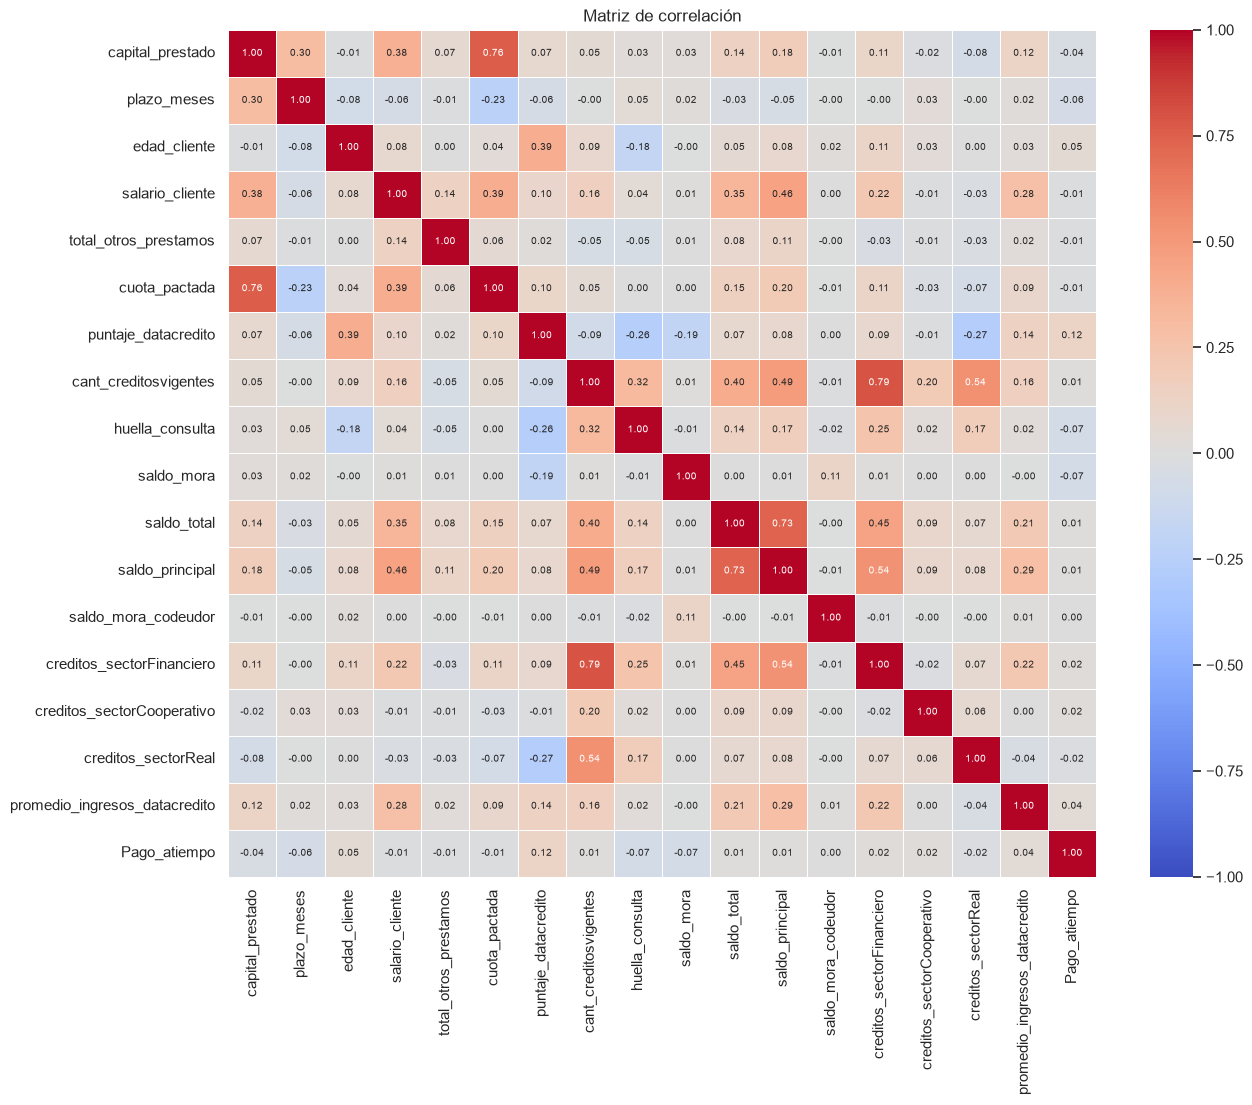

In [36]:
correlacion = datos[numericas + ['Pago_atiempo']].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(correlacion, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5, annot_kws={'size': 7})
plt.title('Matriz de correlación')
plt.show()

In [37]:
print('Correlación con la variable objetivo:')
print(correlacion['Pago_atiempo'].drop('Pago_atiempo').sort_values(key=abs, ascending=False).round(3).head(8))

pares = correlacion.drop(columns='Pago_atiempo').drop(index='Pago_atiempo').abs()
pares = pares.where(np.triu(np.ones(pares.shape, dtype=bool), 1)).stack().sort_values(ascending=False)
print('\nPares de variables más correlacionados:')
print(pares.head(5).round(2))

Correlación con la variable objetivo:
puntaje_datacredito              0.121
huella_consulta                 -0.074
saldo_mora                      -0.073
plazo_meses                     -0.063
edad_cliente                     0.053
capital_prestado                -0.041
promedio_ingresos_datacredito    0.040
creditos_sectorReal             -0.023
Name: Pago_atiempo, dtype: float64

Pares de variables más correlacionados:
cant_creditosvigentes  creditos_sectorFinanciero    0.79
capital_prestado       cuota_pactada                0.76
saldo_total            saldo_principal              0.73
cant_creditosvigentes  creditos_sectorReal          0.54
saldo_principal        creditos_sectorFinanciero    0.54
dtype: float64


- **Con el objetivo:** ninguna variable pasa de 0,12 de correlación (la mayor es `puntaje_datacredito`, 0,12). Es un problema difícil y se espera un desempeño modesto del modelo.
- **Entre variables:** los pares más altos son `cant_creditosvigentes` con `creditos_sectorFinanciero` (0,79), `capital_prestado` con `cuota_pactada` (0,76, normal: la cuota depende del capital) y `saldo_total` con `saldo_principal` (0,73). No son idénticas, así que no se elimina ninguna por ahora (el umbral de alerta que usamos es 0,90).

#### **6.2 Relación entre algunas variables y el objetivo**

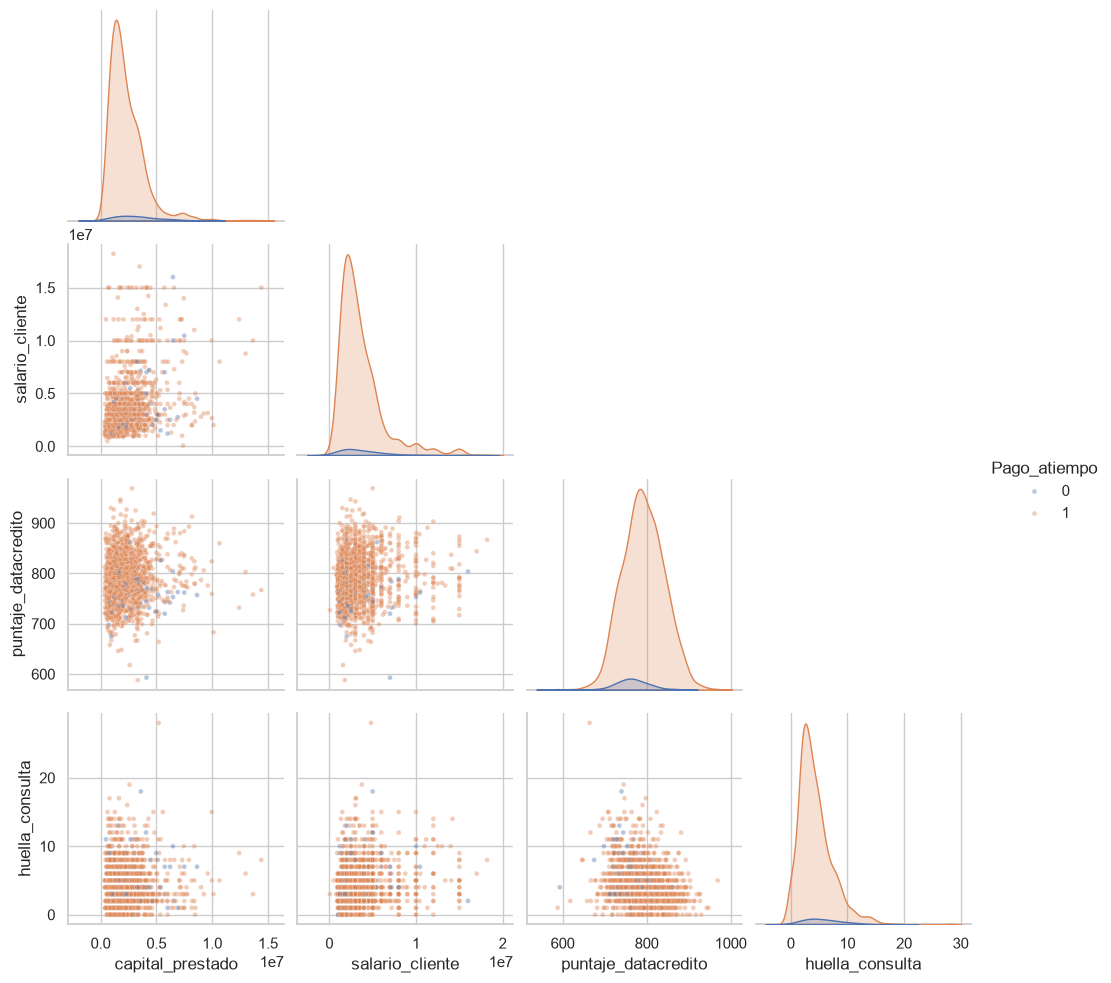

In [38]:
muestra = datos[['capital_prestado', 'salario_cliente', 'puntaje_datacredito', 'huella_consulta', 'Pago_atiempo']].dropna()
muestra = muestra[muestra['salario_cliente'] < muestra['salario_cliente'].quantile(0.99)].sample(1500, random_state=42)

sns.pairplot(muestra, hue='Pago_atiempo', corner=True, plot_kws={'alpha': 0.4, 's': 12})
plt.show()

No se ven grupos separados: los incumplimientos (naranja) quedan mezclados con los pagos a tiempo en todas las combinaciones. Esto confirma que ninguna pareja de variables separa bien las clases.

#### **6.3 Comportamiento en el tiempo**

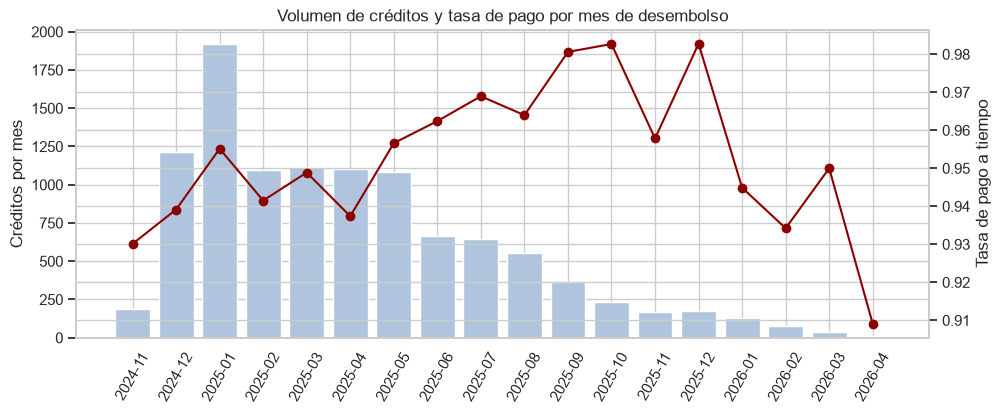

In [39]:
mensual = datos.groupby(datos['fecha_prestamo'].dt.to_period('M'))['Pago_atiempo'].agg(creditos='count', tasa_pago='mean')

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(mensual.index.astype(str), mensual['creditos'], color='lightsteelblue')
ax1.set_ylabel('Créditos por mes')
ax1.tick_params(axis='x', rotation=60)
ax2 = ax1.twinx()
ax2.plot(mensual.index.astype(str), mensual['tasa_pago'], color='darkred', marker='o')
ax2.set_ylabel('Tasa de pago a tiempo')
plt.title('Volumen de créditos y tasa de pago por mes de desembolso')
plt.show()

- El volumen de créditos **cae mucho con el tiempo** (de ~1.900 en enero de 2025 a menos de 100 desde febrero de 2026), entonces la población cambia: hay *drift* y por eso se monitorea.
- La tasa de pago sube en los meses más recientes (de ~94-95% a ~98% en varios meses del segundo semestre de 2025, aunque con pocos créditos por mes y por eso con mucho vaivén). Una **hipótesis** (sin confirmar) es que los créditos recientes han tenido menos tiempo para incumplir. Hay que confirmarlo con el negocio, porque afectaría cómo se separa entrenamiento y prueba.

### **7. Reglas de validación**

Con lo que encontramos, estas son las reglas de calidad que se aplican a los datos (en entrenamiento y en la API). Las revisamos sobre la base original para ver cuántos registros incumplen cada una.

In [40]:
reglas = {
    'edad_cliente entre 18 y 100': db['edad_cliente'].between(18, 100),
    'salario_cliente entre 1 y 100 millones': db['salario_cliente'].between(1, 100_000_000),
    'puntaje_datacredito >= 150': db['puntaje_datacredito'].isnull() | (db['puntaje_datacredito'] >= 150),
    'tendencia_ingresos es Creciente/Estable/Decreciente': db['tendencia_ingresos'].isnull() | db['tendencia_ingresos'].isin(categorias),
    'capital_prestado > 0': db['capital_prestado'] > 0,
    'plazo_meses > 0': db['plazo_meses'] > 0,
    'cuota_pactada > 0': db['cuota_pactada'] > 0,
    'Pago_atiempo es 0 o 1': db['Pago_atiempo'].isin([0, 1]),
    'saldos no negativos': (db[['saldo_mora', 'saldo_total', 'saldo_principal']].fillna(0) >= 0).all(axis=1),
    'saldo_total >= saldo_mora': db['saldo_total'].isnull() | db['saldo_mora'].isnull() | (db['saldo_total'] >= db['saldo_mora']),
}
pd.DataFrame({'registros que incumplen': {r: int((~ok).sum()) for r, ok in reglas.items()}})

,registros que incumplen
edad_cliente entre 18 y 100,150
salario_cliente entre 1 y 100 millones,98
puntaje_datacredito >= 150,147
tendencia_ingresos es Creciente/Estable/Decreciente,58
capital_prestado > 0,0
plazo_meses > 0,0
cuota_pactada > 0,0
Pago_atiempo es 0 o 1,0
saldos no negativos,0
saldo_total >= saldo_mora,0


Las reglas de edad, salario, puntaje de Datacrédito y tendencia de ingresos son las que tienen incumplimientos (150, 98, 147 y 58). Las demás se cumplen hoy y quedan como **controles para datos futuros**. Pendiente confirmar con el negocio los límites de edad (18 a 100) y de salario (100 millones).

### **8. Transformaciones y variables derivadas**

Transformaciones que se aplican después, al construir el modelo (no cambian estos datos):

| Transformación | Para qué |
|---|---|
| Logaritmo (`log1p`) + escalado en los montos | Corregir la asimetría fuerte |
| Imputar con la mediana en las numéricas | Los faltantes son frecuentes y no se pueden borrar filas |
| Categoría "Faltante" en las categóricas | La ausencia de `tendencia_ingresos` es informativa |
| One-Hot en `tipo_credito`, `tipo_laboral` y `tendencia_ingresos` (agrupando los tipos raros) | Pasar categorías a 0/1 |

Variables derivadas que se proponen. Probamos que tan útiles pueden ser comparando su tasa de pago:

In [41]:
derivadas = pd.DataFrame(index=datos.index)
derivadas['cuota_sobre_salario'] = datos['cuota_pactada'] / datos['salario_cliente']
derivadas['tiene_mora'] = (datos['saldo_mora'] > 0).astype(int)
derivadas['total_creditos_sectores'] = datos[['creditos_sectorFinanciero', 'creditos_sectorCooperativo', 'creditos_sectorReal']].sum(axis=1)
derivadas['falta_ingresos'] = datos['promedio_ingresos_datacredito'].isnull().astype(int)
derivadas['Pago_atiempo'] = datos['Pago_atiempo']

print('Tasa de pago por cuartil de cuota_sobre_salario:')
print(derivadas.groupby(pd.qcut(derivadas['cuota_sobre_salario'], 4), observed=True)['Pago_atiempo'].mean().round(3), '\n')
print('Tasa de pago según tiene_mora:')
print(derivadas.groupby('tiene_mora')['Pago_atiempo'].agg(['count', 'mean']).round(3), '\n')
print('Tasa de pago según falta_ingresos:')
print(derivadas.groupby('falta_ingresos')['Pago_atiempo'].agg(['count', 'mean']).round(3))

Tasa de pago por cuartil de cuota_sobre_salario:
cuota_sobre_salario
(0.00083, 0.0391]    0.956
(0.0391, 0.0612]     0.949
(0.0612, 0.0956]     0.956
(0.0956, 125.802]    0.950
Name: Pago_atiempo, dtype: float64 

Tasa de pago según tiene_mora:
            count   mean
tiene_mora              
0           10708  0.954
1              55  0.636 

Tasa de pago según falta_ingresos:
                count   mean
falta_ingresos              
0                7833  0.956
1                2930  0.943


- `tiene_mora` (1 si `saldo_mora` > 0): separa claramente (64% vs 95%).
- `falta_ingresos` (1 si falta el promedio de ingresos): diferencia pequeña pero consistente (94,3% vs 95,6%).
- `cuota_sobre_salario`: **no mostró relación** con el pago (95% en todos los cuartiles). Se deja como candidata, pero no esperamos mucho de ella.
- `total_creditos_sectores`: suma de los tres sectores de crédito (candidata, sin evidencia fuerte).

Además se podrían crear razones como capital/salario y otros préstamos/salario, y el mes del desembolso (si se usa, hay que cuidar el *drift* temporal).

### **9. Conclusiones**

1. La base no tiene filas duplicadas ni fechas imposibles, pero sí **valores imposibles**: 150 edades de 121 a 123 años, 98 salarios en 0 o de miles de millones, 147 puntajes de Datacrédito en 0 y 58 valores numéricos dentro de `tendencia_ingresos`. Se convirtieron en nulo **sin eliminar filas**.
2. Los **faltantes** (~27% en ingresos y tendencia) tienen patrón (más en independientes), por eso se imputan y se marcan con un indicador, no se borran.
3. **`puntaje` se excluye** por posible fuga de datos (correlación 0,92 y AUC = 1,0 por sí sola). Falta confirmar con el negocio cuándo se calcula.
4. La variable objetivo está **muy desbalanceada** (4,75% de incumplimientos), así que se evalúa con recall, precisión y F1 de la clase de incumplimiento y no con *accuracy*.
5. Las señales para predecir son **débiles pero coherentes**: más consultas, mora, plazos largos y puntaje de Datacrédito bajo se asocian con incumplir. Se espera un modelo de desempeño modesto.
6. Los montos son muy asimétricos (se usa logaritmo) y los "atípicos" de mora **no se eliminan** porque son la señal más informativa.
7. Hay **cambio en el tiempo** (cae el volumen de créditos), por lo que se hace monitoreo de *data drift*.

**Pendientes por confirmar:** cuándo se calcula `puntaje`, los límites de edad y salario (incluyendo los 7 salarios menores a 100.000), y si la mejora de la tasa de pago en los meses recientes se debe a que esos créditos han tenido poco tiempo para incumplir.